# Pertemuan 9 — Evaluasi Model Runtun Waktu
## Notebook Praktikum · Analisis Runtun Waktu (SDT-3329)

**Program Studi Sains Data · Fakultas Digital, Desain dan Bisnis · Institut Teknologi Sains Bandung**
Semester 6 · 3 SKS (T: 2, P: 1) · Mata kuliah syarat: Statistika Komputasi, Pemrograman Statistika, Aljabar Linear ·
Dosen pengampu: Bakti Siregar, S.Si., M.Sc

---

### Keselarasan dengan RPS (OBE)

| Komponen | Isi |
|---|---|
| **Kemampuan akhir (Sub-CPMK)** | Mahasiswa mampu menghitung dan menginterpretasi metrik evaluasi peramalan (MSE, RMSE, MAE, MAPE). |
| **CPL / CPMK** | CPL-1 · CPL-3 · CPMK-4 |
| **Indikator** | Mampu menghitung berbagai metrik evaluasi peramalan dan menggunakannya untuk membandingkan kinerja model. |
| **Kriteria penilaian** | Ketepatan perhitungan metrik dan interpretasi hasil evaluasi. |
| **Materi pembelajaran** | Metrik MSE, RMSE, MAE, MAPE, AIC, BIC; perbandingan kinerja model; cross-validation untuk runtun waktu. |
| **Konsep pemrograman** | Generator `yield` untuk *rolling-origin*; *higher-order function* untuk evaluasi; anti-kebocoran waktu (bagian 🧠) |
| **Bobot penilaian minggu ini** | 4% |
| **Alokasi waktu** | TM 2 × 50′ · Praktikum 1 × 170′ · PT 2 × 60′ · BM 2 × 60′ |
| **Keterkaitan tugas (RTM)** | Tugas 2 (P7–P9) — batas akhir |
| **Pustaka** | Hyndman & Athanasopoulos (2021) Bab 5.8–5.10 |

**Dataset:** Airline Passengers · Penjualan mobil bulanan Quebec · deret simulasi
**Pustaka Python:** pandas · NumPy · Matplotlib · seaborn · statsmodels · scikit-learn · SciPy

### Peta notebook

| Bagian | Isi | Indikator RPS |
|---|---|---|
| 1 | Metrik peramalan dari nol: MSE, RMSE, MAE, MAPE, sMAPE, MASE — kelebihan & jebakan | **Menghitung berbagai metrik** |
| 2 | Kriteria informasi (AIC, BIC) vs akurasi di luar sampel; *overfitting* | AIC, BIC |
| 3 | Validasi silang runtun waktu: *rolling origin* (expanding & sliding) vs K-fold acak | Cross-validation untuk runtun waktu |
| 4 | Turnamen model dengan validasi silang: galat per horizon | **Perbandingan kinerja model** |
| 5 | Apakah selisihnya bermakna? Uji Diebold–Mariano | Interpretasi hasil evaluasi |
| 6 | 🧠 Konsep pemrograman: generator lipatan, *higher-order function*, anti-kebocoran | — |
| 7 | Latihan (Tugas 2), ringkasan, logbook | — |

### Cara menggunakan notebook ini

- Jalankan sel berurutan (Google Colab atau Jupyter lokal). Di Colab, `statsmodels` sudah tersedia; `arch` (P11) dipasang dengan `pip install arch`.
- Sel **LATIHAN** berisi `TODO`; lengkapi selama praktikum. Bagian 🧠 **Konsep Pemrograman** menjelaskan prinsip di balik kode,
  bukan sekadar cara memanggil pustaka.
- Penilaian memakai rubrik RPS — *Kualitas Implementasi (Kode & Model)* dan *Interpretasi & Visualisasi Hasil* — serta
  Rubrik PRAKTIKUM (eksekusi 40%, pembersihan data 35%, penanganan error & modularitas 25%).
- Unggah notebook dan logbook ke LMS/Virtual Lab setelah praktikum.

---
## 0. Persiapan

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'figure.figsize': (10, 3.4)})
pd.set_option('display.width', 140)
RANDOM_STATE = 42
import time
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from sklearn.model_selection import TimeSeriesSplit, KFold
from sklearn.linear_model import LinearRegression
from scipy import stats
air = pd.read_csv('https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv', parse_dates=['Month'], index_col='Month')['Passengers'].asfreq('MS')
car = pd.read_csv('https://raw.githubusercontent.com/jbrownlee/Datasets/master/monthly-car-sales.csv', parse_dates=['Month'], index_col='Month')['Sales'].asfreq('MS')

---
## 1. Metrik Evaluasi Peramalan

| Metrik | Rumus | Skala | Catatan |
|---|---|---|---|
| MSE | $\frac1h\sum e_t^2$ | kuadrat satuan | Menghukum galat besar; dasar estimasi |
| **RMSE** | $\sqrt{\text{MSE}}$ | satuan data | Optimal untuk ramalan rata-rata |
| **MAE** | $\frac1h\sum|e_t|$ | satuan data | Kokoh terhadap outlier; optimal untuk median |
| **MAPE** | $\frac{100}h\sum|e_t / y_t|$ | % | Mudah dikomunikasikan; **tak terdefinisi** bila $y_t = 0$, asimetris |
| sMAPE | $\frac{100}h\sum\frac{2|e_t|}{|y_t| + |\hat y_t|}$ | % | Mengurangi asimetri MAPE, tetap bermasalah dekat nol |
| **MASE** | $\text{MAE} / \text{MAE}_{\text{naive musiman, latih}}$ | tanpa satuan | < 1 = lebih baik dari seasonal naive; dapat dibandingkan antar-deret (Hyndman & Koehler, 2006) |

AIC dan BIC (P6) menilai **kecocokan di dalam sampel** dengan hukuman kompleksitas; metrik di atas dihitung **di luar sampel**.

In [ ]:
def galat(y, f): return np.asarray(y, float) - np.asarray(f, float)
def mse(y, f): return float(np.mean(galat(y, f) ** 2))
def rmse(y, f): return float(np.sqrt(mse(y, f)))
def mae(y, f): return float(np.mean(np.abs(galat(y, f))))
def mape(y, f):
    y = np.asarray(y, float)
    if np.any(y == 0):
        raise ValueError('MAPE tak terdefinisi: ada nilai aktual = 0 (gunakan MASE atau sMAPE)')
    return float(100 * np.mean(np.abs(galat(y, f) / y)))
def smape(y, f): return float(100 * np.mean(2 * np.abs(galat(y, f)) / (np.abs(y) + np.abs(f))))
def mase(y, f, y_latih, m=12):
    skala = np.mean(np.abs(np.diff(np.asarray(y_latih, float), n=1) if m == 1 else np.asarray(y_latih)[m:] - np.asarray(y_latih)[:-m]))
    return float(mae(y, f) / skala)
METRIK = {'MAE': mae, 'RMSE': rmse, 'MAPE': mape, 'sMAPE': smape}

latih, uji = air[:-24], air[-24:]
f_sn = np.tile(latih.iloc[-12:].values, 2)
f_sar = np.exp(SARIMAX(np.log(latih), order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False).forecast(24))
tab = pd.DataFrame({nama: {k: f(uji, ff) for k, f in METRIK.items()} | {'MASE': mase(uji, ff, latih)}
                    for nama, ff in [('Seasonal naive', f_sn), ('SARIMA airline', f_sar)]}).T
print(tab.round(3))

                   MAE    RMSE    MAPE   sMAPE   MASE
Seasonal naive  71.250  76.995  15.523  17.013  2.494
SARIMA airline  39.437  43.173   8.514   8.949  1.380


In [ ]:
# Jebakan metrik
y_nol = np.array([0.0, 5, 10]); f_nol = np.array([1.0, 5, 10])
try:
    mape(y_nol, f_nol)
except ValueError as e:
    print('MAPE ->', e)
print(f'Asimetri MAPE: aktual 100, ramalan 150 -> {mape([100], [150]):.0f}% | aktual 150, ramalan 100 -> {mape([150], [100]):.1f}%')
outlier = np.r_[np.full(23, 10.0), 100.0]; f_rata = np.full(24, 10.0)
print(f'Satu galat besar: MAE = {mae(outlier, f_rata):.2f}, RMSE = {rmse(outlier, f_rata):.2f} (RMSE ≥ MAE, peka galat besar)')
print(f'Skala: RMSE Airline dalam ribu penumpang = {rmse(uji, f_sar):.1f}; dalam penumpang = {rmse(uji*1000, f_sar*1000):,.0f}; MAPE sama {mape(uji, f_sar):.2f}%')

MAPE -> MAPE tak terdefinisi: ada nilai aktual = 0 (gunakan MASE atau sMAPE)
Asimetri MAPE: aktual 100, ramalan 150 -> 50% | aktual 150, ramalan 100 -> 33.3%
Satu galat besar: MAE = 3.75, RMSE = 18.37 (RMSE ≥ MAE, peka galat besar)
Skala: RMSE Airline dalam ribu penumpang = 43.2; dalam penumpang = 43,173; MAPE sama 8.51%


> **Memilih metrik:** gunakan MAE/RMSE untuk membandingkan model pada **satu** deret (satuan yang bermakna bagi bisnis),
> MASE untuk membandingkan **antar-deret**, dan MAPE hanya bila data jauh dari nol. Laporkan lebih dari satu metrik —
> model terbaik menurut RMSE belum tentu terbaik menurut MAE.

---
## 2. Kecocokan di Dalam Sampel vs Akurasi di Luar Sampel

Model yang lebih kompleks hampir selalu memperkecil galat **latih**, tetapi belum tentu memperkecil galat **ramalan**.

                         parameter  RMSE latih       AIC       BIC  RMSE uji
derajat tren polinomial                                                     
1                               13      0.0517 -684.8382 -648.6008    0.1033
2                               14      0.0461 -710.2666 -671.2417    0.0476
3                               15      0.0451 -713.6730 -671.8606    0.0888
5                               17      0.0391 -744.2236 -696.8362    0.8970
7                               19      0.0356 -762.7035 -709.7412    1.2728
9                               21      0.0352 -761.3333 -702.7960    1.2183


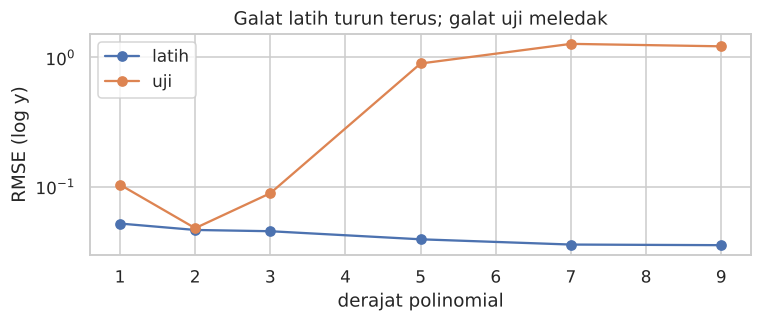

In [ ]:
ly = np.log(air)
t_all = np.arange(len(ly)) / len(ly)                         # waktu dinormalkan 0..1 (stabil secara numerik)
bulan = pd.get_dummies(ly.index.month, drop_first=True).values.astype(float)
n_l = len(ly) - 24
baris = []
for derajat in [1, 2, 3, 5, 7, 9]:
    X = np.column_stack([t_all ** k for k in range(1, derajat + 1)] + [bulan])
    m = LinearRegression().fit(X[:n_l], ly.values[:n_l])
    e_l = ly.values[:n_l] - m.predict(X[:n_l]); k = X.shape[1] + 1
    aic = n_l * np.log(np.mean(e_l ** 2)) + 2 * k; bic = n_l * np.log(np.mean(e_l ** 2)) + k * np.log(n_l)
    baris.append({'derajat tren polinomial': derajat, 'parameter': k, 'RMSE latih': rmse(ly.values[:n_l], m.predict(X[:n_l])),
                  'AIC': aic, 'BIC': bic, 'RMSE uji': rmse(ly.values[n_l:], m.predict(X[n_l:]))})
t = pd.DataFrame(baris).set_index('derajat tren polinomial')
print(t.round(4))
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(t.index, t['RMSE latih'], 'o-', label='latih'); ax.plot(t.index, t['RMSE uji'], 'o-', label='uji')
ax.set_yscale('log'); ax.set_xlabel('derajat polinomial'); ax.set_ylabel('RMSE (log y)'); ax.legend()
ax.set_title('Galat latih turun terus; galat uji meledak'); plt.tight_layout(); plt.show()

> Model regresi log Airline dengan tren polinomial + dummy bulan: makin tinggi derajat polinomial, galat **latih** makin
> kecil, tetapi ramalan **uji** memburuk drastis — polinomial derajat tinggi melengkung liar di luar rentang data
> (*overfitting* + ekstrapolasi). Yang mengejutkan: **AIC dan BIC sama-sama memilih derajat 7**, padahal RMSE ujinya ±27 kali
> lebih buruk daripada derajat 2. Kriteria informasi hanya melihat data latih — perbaikan kecocokan di dalam sampel melebihi
> hukuman kompleksitas, sementara bahaya ekstrapolasi tidak terlihat sama sekali; **hanya evaluasi di luar sampel** yang menunjukkan biaya sebenarnya. Satu periode uji 24 bulan
> tetap terlalu sedikit untuk kesimpulan yang stabil → validasi silang.

---
## 3. Validasi Silang Runtun Waktu

**K-fold acak dilarang:** lipatan uji dapat berada di **tengah** data latih, sehingga model belajar dari masa depan.
**Rolling origin** (*evaluation on a rolling forecasting origin*): titik asal ramalan maju selangkah demi selangkah;
model selalu dilatih dengan data **sebelum** asal dan diuji pada h langkah sesudahnya.

| Skema | Data latih | Cocok bila |
|---|---|---|
| **Expanding window** | Semua data sejak awal sampai asal | Pola stabil; data terbatas |
| **Sliding window** | w pengamatan terakhir sebelum asal | Pola berubah; data lama kurang relevan |

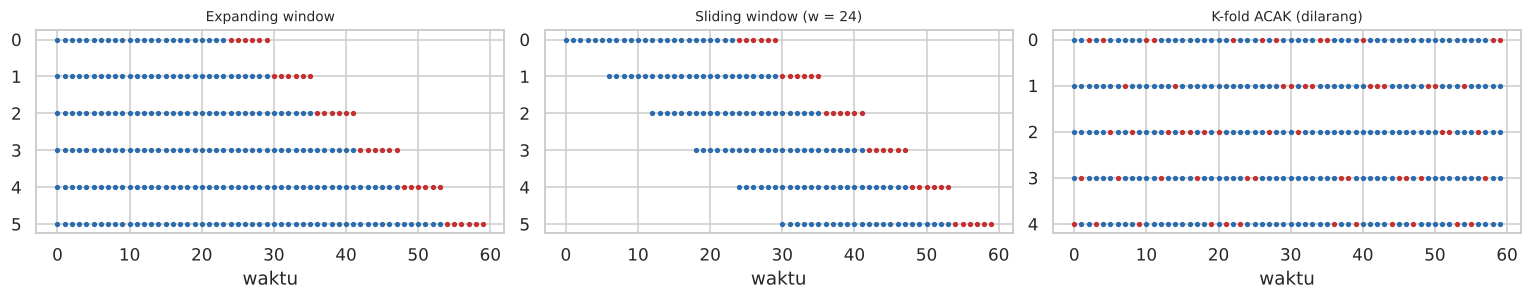

Pembanding scikit-learn TimeSeriesSplit: [(np.int64(35), np.int64(36), np.int64(41)), (np.int64(41), np.int64(42), np.int64(47)), (np.int64(47), np.int64(48), np.int64(53)), (np.int64(53), np.int64(54), np.int64(59))]


In [ ]:
def rolling_origin(n, awal, h=12, langkah=1, jendela=None):
    """GENERATOR: menghasilkan (indeks_latih, indeks_uji) dengan asal ramalan bergeser maju.
    jendela=None -> expanding window; jendela=w -> sliding window sepanjang w."""
    if awal + h > n:
        raise ValueError('data terlalu pendek untuk awal + h')
    for asal in range(awal, n - h + 1, langkah):
        mulai = 0 if jendela is None else max(0, asal - jendela)
        yield np.arange(mulai, asal), np.arange(asal, asal + h)

fig, axs = plt.subplots(1, 3, figsize=(14, 2.8))
for a, (j, gen) in zip(axs, [('Expanding window', rolling_origin(60, 24, h=6, langkah=6)),
                             ('Sliding window (w = 24)', rolling_origin(60, 24, h=6, langkah=6, jendela=24)),
                             ('K-fold ACAK (dilarang)', ((np.setdiff1d(np.arange(60), te), te) for _, te in KFold(5, shuffle=True, random_state=0).split(np.arange(60))))]):
    for i, (tr, te) in enumerate(gen):
        a.scatter(tr, [i] * len(tr), color='#2b6cb0', s=6); a.scatter(te, [i] * len(te), color='#c53030', s=6)
    a.set_title(j, fontsize=9); a.set_xlabel('waktu'); a.invert_yaxis()
plt.tight_layout(); plt.show()
print('Pembanding scikit-learn TimeSeriesSplit:', [(tr[-1], te[0], te[-1]) for tr, te in TimeSeriesSplit(n_splits=4, test_size=6).split(np.arange(60))])

In [ ]:
# Bukti kebocoran: model fleksibel (random forest) pada fitur waktu & bulan
from sklearn.ensemble import RandomForestRegressor
d = pd.DataFrame({'y': np.log(air).values, 't': np.arange(len(air)), 'bulan': air.index.month})
X, y = d[['t', 'bulan']].values, d.y.values
def cv_skor(lipatan):
    return np.mean([rmse(y[te], RandomForestRegressor(200, random_state=0).fit(X[tr], y[tr]).predict(X[te])) for tr, te in lipatan])
print(f'RMSE K-fold acak          : {cv_skor(KFold(5, shuffle=True, random_state=0).split(X)):.4f}  (interpolasi — terlalu optimistis)')
print(f'RMSE rolling origin (h=12): {cv_skor(rolling_origin(len(y), 72, h=12, langkah=12)):.4f}  (ekstrapolasi — jujur)')

RMSE K-fold acak          : 0.0802  (interpolasi — terlalu optimistis)


RMSE rolling origin (h=12): 0.1325  (ekstrapolasi — jujur)


> Dengan K-fold acak, random forest cukup "mengisi celah" di antara bulan-bulan yang sudah dilihatnya (interpolasi) —
> galatnya kecil. Dengan rolling origin, ia harus meramal **masa depan** dan tidak mampu mengekstrapolasi tren (pohon hanya
> memprediksi nilai dalam rentang latih), sehingga galatnya berlipat. Validasi yang salah akan memilih model yang salah.

---
## 4. Turnamen Model dengan Validasi Silang

21 asal ramalan × 4 model dalam 4.8 dtk
                      MAE (h=1..12)  MAE h=1  MAE h=12  MASE vs snaive
SARIMA airline (log)          14.52     6.33     20.18            0.37
HW multiplikatif              15.58     6.59     19.99            0.40
Seasonal naive                38.80    38.38     36.71            1.00
Drift                         54.67    28.93     19.05            1.41


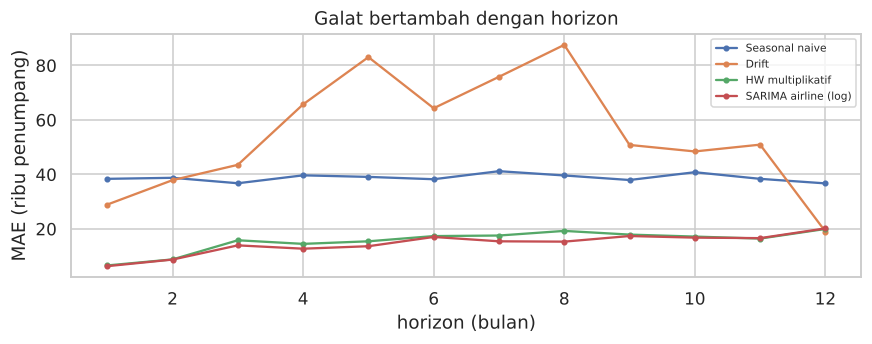

In [ ]:
def evaluasi_cv(pembuat_ramalan, y, awal=72, h=12, langkah=3, jendela=None):
    """HIGHER-ORDER: `pembuat_ramalan(y_latih, h)` -> array ramalan. Mengembalikan matriks galat absolut (lipatan x horizon)."""
    E = []
    for tr, te in rolling_origin(len(y), awal, h, langkah, jendela):
        f = pembuat_ramalan(y.iloc[tr], h)
        E.append(np.abs(y.iloc[te].values - np.asarray(f)))
    return np.array(E)

def snaive(yl, h): return np.resize(yl.iloc[-12:].values, h)
def drift(yl, h): return yl.iloc[-1] + (yl.iloc[-1] - yl.iloc[0]) / (len(yl) - 1) * np.arange(1, h + 1)
def hw_mul(yl, h): return ExponentialSmoothing(yl, trend='add', seasonal='mul', seasonal_periods=12, initialization_method='estimated').fit().forecast(h)
def sarima_log(yl, h): return np.exp(SARIMAX(np.log(yl), order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False).forecast(h))

hasil = {}
t0 = time.time()
for nama, f in [('Seasonal naive', snaive), ('Drift', drift), ('HW multiplikatif', hw_mul), ('SARIMA airline (log)', sarima_log)]:
    hasil[nama] = evaluasi_cv(f, air)
n_lipatan = len(next(iter(hasil.values())))
print(f'{n_lipatan} asal ramalan × 4 model dalam {time.time()-t0:.1f} dtk')
ringkas = pd.DataFrame({k: {'MAE (h=1..12)': E.mean(), 'MAE h=1': E[:, 0].mean(), 'MAE h=12': E[:, -1].mean(),
                            'MASE vs snaive': E.mean() / hasil['Seasonal naive'].mean()} for k, E in hasil.items()}).T
print(ringkas.round(2).sort_values('MAE (h=1..12)'))
fig, ax = plt.subplots(figsize=(8, 3.2))
for k, E in hasil.items(): ax.plot(range(1, 13), E.mean(axis=0), 'o-', label=k, ms=3)
ax.set_xlabel('horizon (bulan)'); ax.set_ylabel('MAE (ribu penumpang)'); ax.legend(fontsize=7); ax.set_title('Galat bertambah dengan horizon')
plt.tight_layout(); plt.show()

> Dengan banyak asal ramalan, peringkat model jauh lebih dapat dipercaya daripada satu pembagian latih–uji (bandingkan
> dengan P5 dan P7, di mana urutan berubah bergantung pada periode uji). Galat semua model bertambah dengan horizon; laporan
> evaluasi sebaiknya menyebut horizon yang relevan bagi keputusan (mis. 3 bulan untuk pengadaan, 12 bulan untuk anggaran).

---
## 5. Apakah Selisihnya Bermakna? Uji Diebold–Mariano

H₀: dua metode sama akurat. Statistik $DM = \bar d / \sqrt{\widehat{\text{Var}}(\bar d)}$ dengan $d_t = |e_{1,t}| - |e_{2,t}|$
(atau kuadrat galat). Varians memperhitungkan autokorelasi $d_t$ hingga lag h−1.

In [ ]:
def diebold_mariano(e1, e2, h=1, kuadrat=False):
    """Uji DM dari nol (dengan koreksi Harvey dkk., 1997). e1, e2: galat dua metode pada titik yang sama."""
    d = (np.square(e1) - np.square(e2)) if kuadrat else (np.abs(e1) - np.abs(e2))
    n, dbar = len(d), d.mean()
    gamma = [np.sum((d[k:] - dbar) * (d[:n - k] - dbar)) / n for k in range(h)]
    var = (gamma[0] + 2 * sum(gamma[1:])) / n
    if var <= 0:                                   # estimasi varians dapat negatif pada sampel kecil -> pakai gamma0 saja
        var = gamma[0] / n
    dm = dbar / np.sqrt(var) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return dm, 2 * stats.t.sf(abs(dm), df=n - 1)

for h_ in [1, 12]:
    for a, b in [('HW multiplikatif', 'SARIMA airline (log)'), ('Seasonal naive', 'SARIMA airline (log)')]:
        lag = int(np.ceil(h_ / 3))                       # asal maju 3 bulan -> galat horizon h tumpang tindih ±h/3 lipatan
        dm, p = diebold_mariano(hasil[a][:, h_ - 1], hasil[b][:, h_ - 1], h=lag)
        print(f'h={h_:>2} | {a} vs {b}: DM = {dm:+.2f}, p = {p:.3f}')

h= 1 | HW multiplikatif vs SARIMA airline (log): DM = +0.28, p = 0.782
h= 1 | Seasonal naive vs SARIMA airline (log): DM = +8.67, p = 0.000
h=12 | HW multiplikatif vs SARIMA airline (log): DM = -0.04, p = 0.971
h=12 | Seasonal naive vs SARIMA airline (log): DM = +1.29, p = 0.211


> DM positif berarti metode pertama memiliki galat lebih besar. SARIMA jelas lebih baik dari seasonal naive, tetapi selisih
> SARIMA vs Holt-Winters (14,5 vs 15,6) **tidak signifikan** — kedua model sama-sama layak. Pada horizon 12 bahkan keunggulan
> atas seasonal naive tidak signifikan (p ≈ 0,21): dengan 21 asal yang saling tumpang tindih, bukti statistiknya lemah. Catatan: titik evaluasi dari rolling origin saling tumpang tindih sehingga
> uji ini bersifat perkiraan; tetap jauh lebih informatif daripada membandingkan dua angka MAPE tunggal.

---
## 6. 🧠 Konsep Pemrograman — Generator, Higher-Order Function, Anti-Kebocoran

| Konsep | Di notebook ini |
|---|---|
| **Generator (`yield`)** | `rolling_origin` menghasilkan lipatan satu per satu — tidak menyimpan semua indeks; dapat dipakai untuk data sangat panjang |
| **Higher-order function** | `evaluasi_cv(pembuat_ramalan, ...)` menerima fungsi peramal apa pun — model baru cukup ditulis sebagai fungsi `f(y_latih, h)` |
| **Kontrak fungsi** | Semua peramal: masukan = Series latih + h, keluaran = array panjang h |
| **Anti-kebocoran by design** | Peramal hanya menerima `y.iloc[tr]`; secara struktural tidak mungkin melihat data uji |
| **Validasi masukan** | Galat bila `awal + h > n`; MAPE menolak nilai nol |

In [ ]:
# Uji sifat (property test) generator: tidak ada indeks uji yang <= indeks latih terakhir, dan horizon selalu h
for tr, te in rolling_origin(100, 30, h=7, langkah=5, jendela=20):
    assert tr.max() < te.min(), 'kebocoran!'
    assert len(te) == 7 and len(tr) <= 20
print('Sifat generator terverifikasi ✓')

# Menambah model baru tanpa mengubah evaluasi_cv: cukup satu fungsi
def rata_musiman_3th(yl, h):
    pola = yl.iloc[-36:].groupby(yl.index[-36:].month).mean()
    bulan = pd.date_range(yl.index[-1] + pd.offsets.MonthBegin(), periods=h, freq='MS').month
    return pola.loc[bulan].values * (yl.iloc[-12:].mean() / yl.iloc[-36:].mean())
E = evaluasi_cv(rata_musiman_3th, air)
print(f'Model baru "rata-rata musiman 3 tahun": MAE = {E.mean():.2f} (bandingkan tabel Bagian 4)')

Sifat generator terverifikasi ✓
Model baru "rata-rata musiman 3 tahun": MAE = 38.97 (bandingkan tabel Bagian 4)


---
## 7. Latihan

### LATIHAN 1 — Tugas 2, langkah 5
Hitung MAE, RMSE, MAPE (dan MASE) untuk semua model Tugas 2 Anda, baik pada satu periode uji maupun dengan rolling origin.
Apakah peringkat model berubah?

In [ ]:
# TODO

### LATIHAN 2 — Sliding vs expanding
Ulangi turnamen Bagian 4 dengan sliding window 60 bulan. Untuk model mana sliding window membantu, dan mengapa?

In [ ]:
# TODO

### LATIHAN 3 — Penjualan mobil
Jalankan turnamen yang sama pada penjualan mobil Quebec (awal = 60). Bandingkan kesimpulan dengan perbandingan satu kali di P5.

In [ ]:
# TODO

---
## 8. Ringkasan Pertemuan 9

- ▸ MAE/RMSE (satuan data), MAPE/sMAPE (persen, waspadai nol), MASE (antar-deret, pembanding seasonal naive).
- ▸ AIC/BIC menilai kecocokan dalam sampel; akurasi ramalan dinilai di luar sampel — keduanya bisa berbeda.
- ▸ Validasi silang runtun waktu = rolling origin (expanding/sliding); K-fold acak membocorkan masa depan.
- ▸ Laporkan galat per horizon; uji Diebold–Mariano untuk menilai apakah selisih bermakna.

### Tugas mandiri (PT & BM) — **Tugas 2 dikumpulkan**
Laporan PDF + notebook GitHub: pemulusan, ARIMA/SARIMA, metrik, diagnostik residual (pelajari P10 terlebih dahulu bila perlu).

**Pertemuan berikutnya:** `P10_Diagnostik_Model.ipynb`

---
## Logbook Praktikum — Pertemuan 9

Salin sel di bawah, isi, lalu unggah bersama notebook ke LMS/Virtual Lab (aktivitas PT & BM sesuai RPS).

In [ ]:
logbook = {
    'Nama / NIM'                          : 'TODO',
    'Pertemuan'                           : 9,
    'Tanggal praktikum'                   : 'TODO',
    'Tiga temuan terpenting (dengan angka)': ['TODO', 'TODO', 'TODO'],
    'Galat yang ditemui & cara mengatasi' : 'TODO',
    'Latihan yang diselesaikan'           : 'TODO',
    'Pertanyaan untuk pertemuan berikutnya': 'TODO',
}
for k, v in logbook.items():
    print(f'{k:<38}: {v}')

Nama / NIM                            : TODO
Pertemuan                             : 9
Tanggal praktikum                     : TODO
Tiga temuan terpenting (dengan angka) : ['TODO', 'TODO', 'TODO']
Galat yang ditemui & cara mengatasi   : TODO
Latihan yang diselesaikan             : TODO
Pertanyaan untuk pertemuan berikutnya : TODO
